                  RESUME DATASET c199D.dat                     
1. Jumlah Total Node      : 101 (1 Depot Pusat & 100 Pelanggan)
2. Koordinat Depot (ID 0) : X = 35, Y = 35
3. Total Permintaan (Demand) Pelanggan : 1458 unit
4. Rata-rata Demand per Pelanggan      : 14.58 unit
5. Rentang Demand Pelanggan            : 1 s/d 41 unit
6. Rentang Waktu Kesiapan (Time Avail)  : 2 s/d 374
7. Jarak Rata-rata Pelanggan ke Depot   : 24.95 satuan jarak
8. Pelanggan Terjauh dari Depot         : ID 65 (Jarak: 49.93 satuan)

=== 20 BARIS PERTAMA DATA PELANGGAN (c199D.dat) ===


,ID,X,Y,Demand,Duration,Time_Avail,Distance_To_Depot
1,1,41,49,10,12,2,15.23
2,2,35,17,7,12,9,18.00
3,3,55,45,13,12,9,22.36
4,4,55,20,19,12,16,25.00
5,5,15,30,26,12,17,20.62
6,6,25,30,3,12,22,11.18
7,7,20,50,5,12,28,21.21
8,8,10,43,9,12,35,26.25
9,9,55,60,16,12,41,32.02
10,10,30,60,16,12,47,25.50



=== RINGKASAN STATISTIK DESKRIPTIF ===


,X,Y,Demand,Time_Avail,Distance_To_Depot
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,33.700000,35.920000,14.580000,179.080000,24.947200
std,18.364711,19.485649,8.870767,107.440252,9.533141
min,2.000000,3.000000,1.000000,2.000000,4.470000
25%,18.750000,20.000000,8.000000,85.250000,18.030000
50%,31.000000,34.500000,13.000000,167.000000,24.880000
75%,49.000000,52.000000,19.250000,275.250000,31.687500
max,67.000000,77.000000,41.000000,374.000000,49.930000


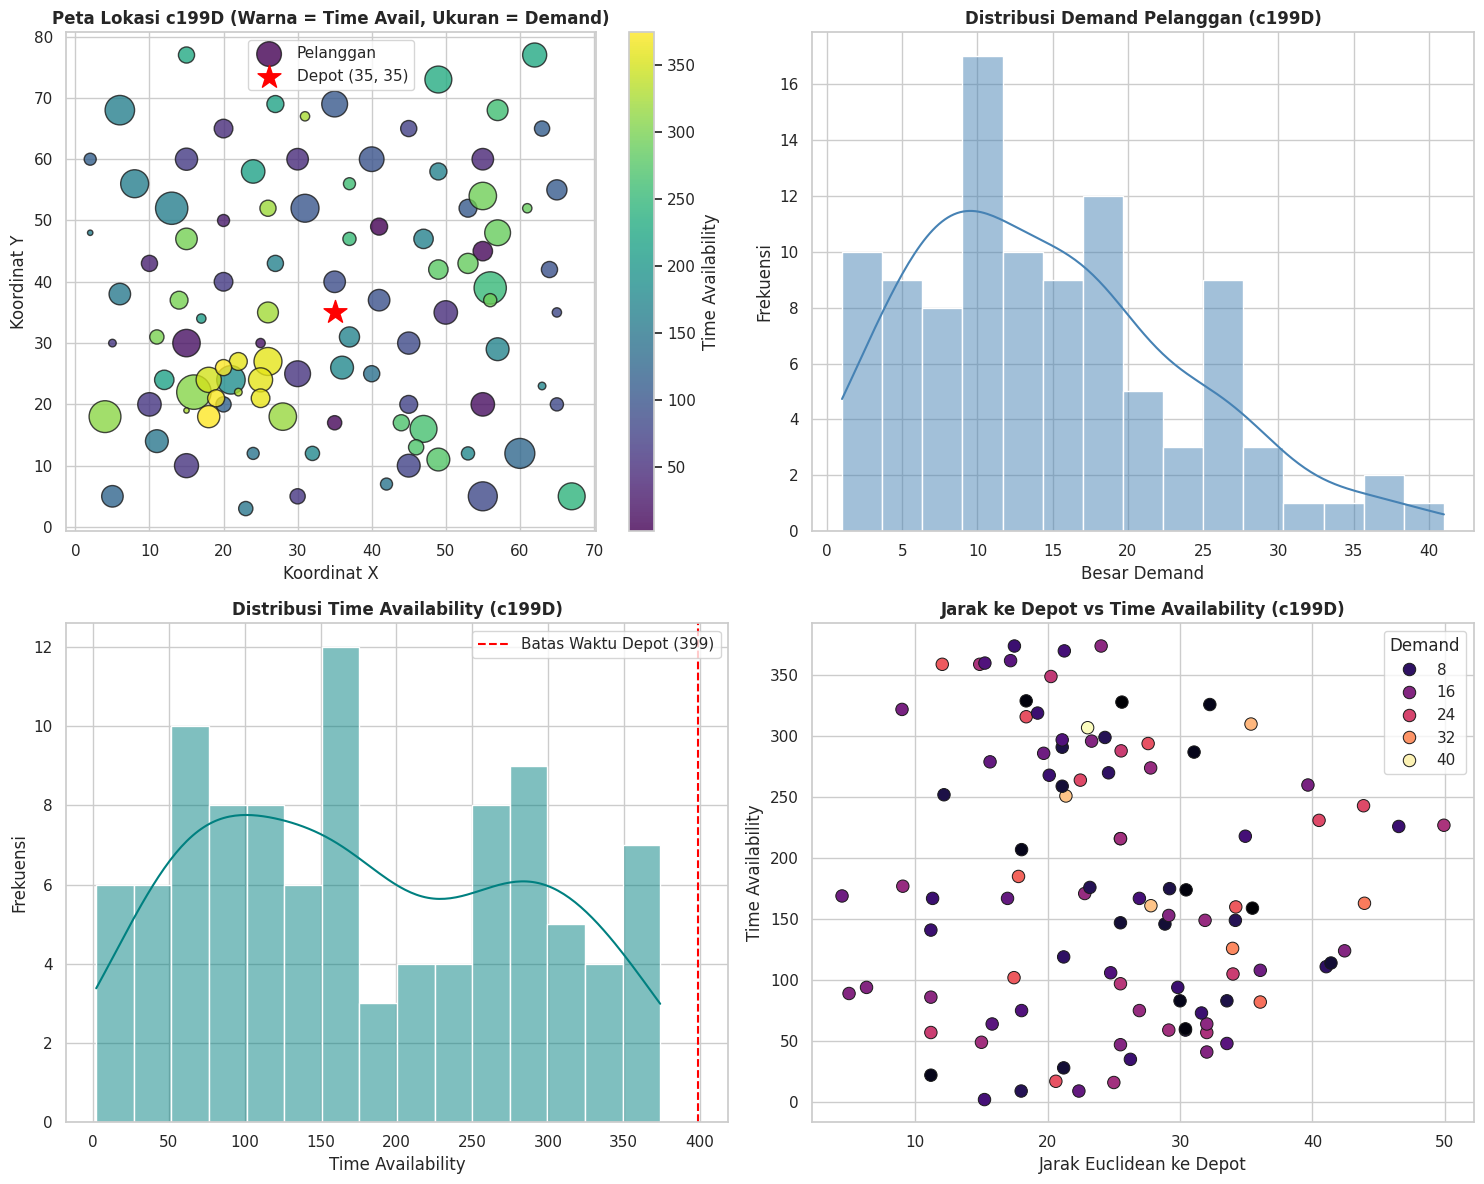

In [1]:
#Deskripsi dataset

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

file_path = '/content/drive/MyDrive/DATASET TUGAS/DVRP Kilbys instances for Dynamic Vehicle Routing Problem/c100D.dat'

demands = {}
coords = {}
time_avails = {}
current_sec = None

with open(file_path, 'r') as file:
  for line in file:
    line = line.strip()
    if line == 'DEMAND_SECTION':
      current_sec = 'DEMAND'
      continue
    elif line == 'LOCATION_COORD_SECTION':
      current_sec = 'COORD'
      continue
    elif line == 'TIME_AVAIL_SECTION':
      current_sec = 'TIME_AVAIL'
      continue
    elif not line or not line.split()[0].isdigit():
      current_sec = None
      continue

    parts = line.split()
    if current_sec == 'DEMAND':
      demands[int(parts[0])] = abs(int(parts[1]))
    elif current_sec == 'COORD':
      coords[int(parts[0])] = (int(parts[1]), int(parts[2]))
    elif current_sec == 'TIME_AVAIL':
      time_avails[int(parts[0])] = int(parts[1])

df_list = []
max_id = max(coords.keys()) if coords else 0

for i in range(max_id + 1):
    x, y = coords.get(i, (0, 0))
    df_list.append({
        'ID': i,
        'Type': 'Depot' if i == 0 else 'Customer',
        'X': x,
        'Y': y,
        'Demand': demands.get(i, 0),
        'Duration': 0 if i == 0 else 12,
        'Time_Avail': time_avails.get(i, 0),
    })

df = pd.DataFrame(df_list)

depot = df[df['Type'] == 'Depot'].iloc[0]
customers = df[df['Type'] == 'Customer'].copy()
customers['Distance_To_Depot'] = np.sqrt(
    (customers['X'] - depot['X']) ** 2 + (customers['Y'] - depot['Y']) ** 2
).round(2)

print('===============================================================')
print('                  RESUME DATASET c199D.dat                     ')
print('===============================================================')
print(f'1. Jumlah Total Node      : {len(df)} (1 Depot Pusat & {len(customers)} Pelanggan)')
print(f'2. Koordinat Depot (ID 0) : X = {depot["X"]}, Y = {depot["Y"]}')
print(f'3. Total Permintaan (Demand) Pelanggan : {customers["Demand"].sum()} unit')
print(f'4. Rata-rata Demand per Pelanggan      : {customers["Demand"].mean():.2f} unit')
print(f'5. Rentang Demand Pelanggan            : {customers["Demand"].min()} s/d {customers["Demand"].max()} unit')
print(f'6. Rentang Waktu Kesiapan (Time Avail)  : {customers["Time_Avail"].min()} s/d {customers["Time_Avail"].max()}')
print(f'7. Jarak Rata-rata Pelanggan ke Depot   : {customers["Distance_To_Depot"].mean():.2f} satuan jarak')
print(f'8. Pelanggan Terjauh dari Depot         : ID {customers.loc[customers["Distance_To_Depot"].idxmax(), "ID"]} (Jarak: {customers["Distance_To_Depot"].max()} satuan)')
print('===============================================================\n')

print('=== 20 BARIS PERTAMA DATA PELANGGAN (c199D.dat) ===')
display(
    customers[
        ['ID', 'X', 'Y', 'Demand', 'Duration', 'Time_Avail', 'Distance_To_Depot']
    ].head(20)
)

print("\n=== RINGKASAN STATISTIK DESKRIPTIF ===")
display(
    customers[
        ['X', 'Y', 'Demand', 'Time_Avail', 'Distance_To_Depot']
    ].describe()
)

sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

scatter = axes[0, 0].scatter(
    customers['X'],
    customers['Y'],
    c=customers['Time_Avail'],
    cmap='viridis',
    s=customers['Demand'] * 15,
    alpha=0.8,
    edgecolors='k',
    label='Pelanggan',
)
axes[0, 0].scatter(
    depot['X'],
    depot['Y'],
    color='red',
    marker='*',
    s=300,
    label=f"Depot ({depot['X']}, {depot['Y']})",
)
axes[0, 0].set_title(
    'Peta Lokasi c199D (Warna = Time Avail, Ukuran = Demand)',
    fontsize=12,
    fontweight='bold',
)
axes[0, 0].set_xlabel('Koordinat X')
axes[0, 0].set_ylabel('Koordinat Y')
plt.colorbar(scatter, ax=axes[0, 0], label='Time Availability')
axes[0, 0].legend()

sns.histplot(
    customers['Demand'], bins=15, ax=axes[0, 1], color='steelblue', kde=True
)
axes[0, 1].set_title(
    'Distribusi Demand Pelanggan (c199D)', fontsize=12, fontweight='bold'
)
axes[0, 1].set_xlabel('Besar Demand')
axes[0, 1].set_ylabel('Frekuensi')

sns.histplot(
    customers['Time_Avail'], kde=True, bins=15, ax=axes[1, 0], color='teal'
)
axes[1, 0].axvline(
    399, color='red', linestyle='--', label='Batas Waktu Depot (399)'
)
axes[1, 0].set_title(
    'Distribusi Time Availability (c199D)', fontsize=12, fontweight='bold'
)
axes[1, 0].set_xlabel('Time Availability')
axes[1, 0].set_ylabel('Frekuensi')
axes[1, 0].legend()

sns.scatterplot(
    data=customers,
    x='Distance_To_Depot',
    y='Time_Avail',
    hue='Demand',
    palette='magma',
    s=80,
    ax=axes[1, 1],
    edgecolor='k',
)
axes[1, 1].set_title(
    'Jarak ke Depot vs Time Availability (c199D)',
    fontsize=12,
    fontweight='bold',
)
axes[1, 1].set_xlabel('Jarak Euclidean ke Depot')
axes[1, 1].set_ylabel('Time Availability')

plt.tight_layout()
plt.show()

=== 1. UKURAN DATASET (SHAPE) ===
Jumlah Baris (Pelanggan) : 100
Jumlah Kolom              : 8

=== 2. TIPE DATA & INFORMASI STRUKTUR KOLOM ===


,Tipe Data,Jumlah Non-Null,Jumlah Null,Persentase Null (%),Jumlah Unique Value
ID,int64,100,0,0.0,100
Type,object,100,0,0.0,1
X,int64,100,0,0.0,50
Y,int64,100,0,0.0,48
Demand,int64,100,0,0.0,32
Duration,int64,100,0,0.0,1
Time_Avail,int64,100,0,0.0,87
Distance_To_Depot,float64,100,0,0.0,81



=== 3. RINGKASAN PEMERIKSAAN KUALITAS DATA ===


,Parameter Identifikasi,Jumlah Ditemukan,Status
0,Missing Values (Data Hilang),0,BERSIH
1,Duplikasi Baris (Full Duplicate),0,BERSIH
2,Duplikasi ID Pelanggan,0,BERSIH
3,"Duplikasi Lokasi (Koordinat X, Y SAMA)",0,BERSIH
4,Demand Inkonsisten (<= 0),0,BERSIH
5,Time Avail Inkonsisten (< 0),0,BERSIH
6,Time Avail Melebihi Batas Depot (> 399),0,BERSIH
7,Jarak Inkonsisten (<= 0),0,BERSIH


/tmp/ipykernel_4484/2580954139.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_4484/2580954139.py:99: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[0, 1].set_xticklabels(axes[0, 1].get_xticklabels(), rotation=30)


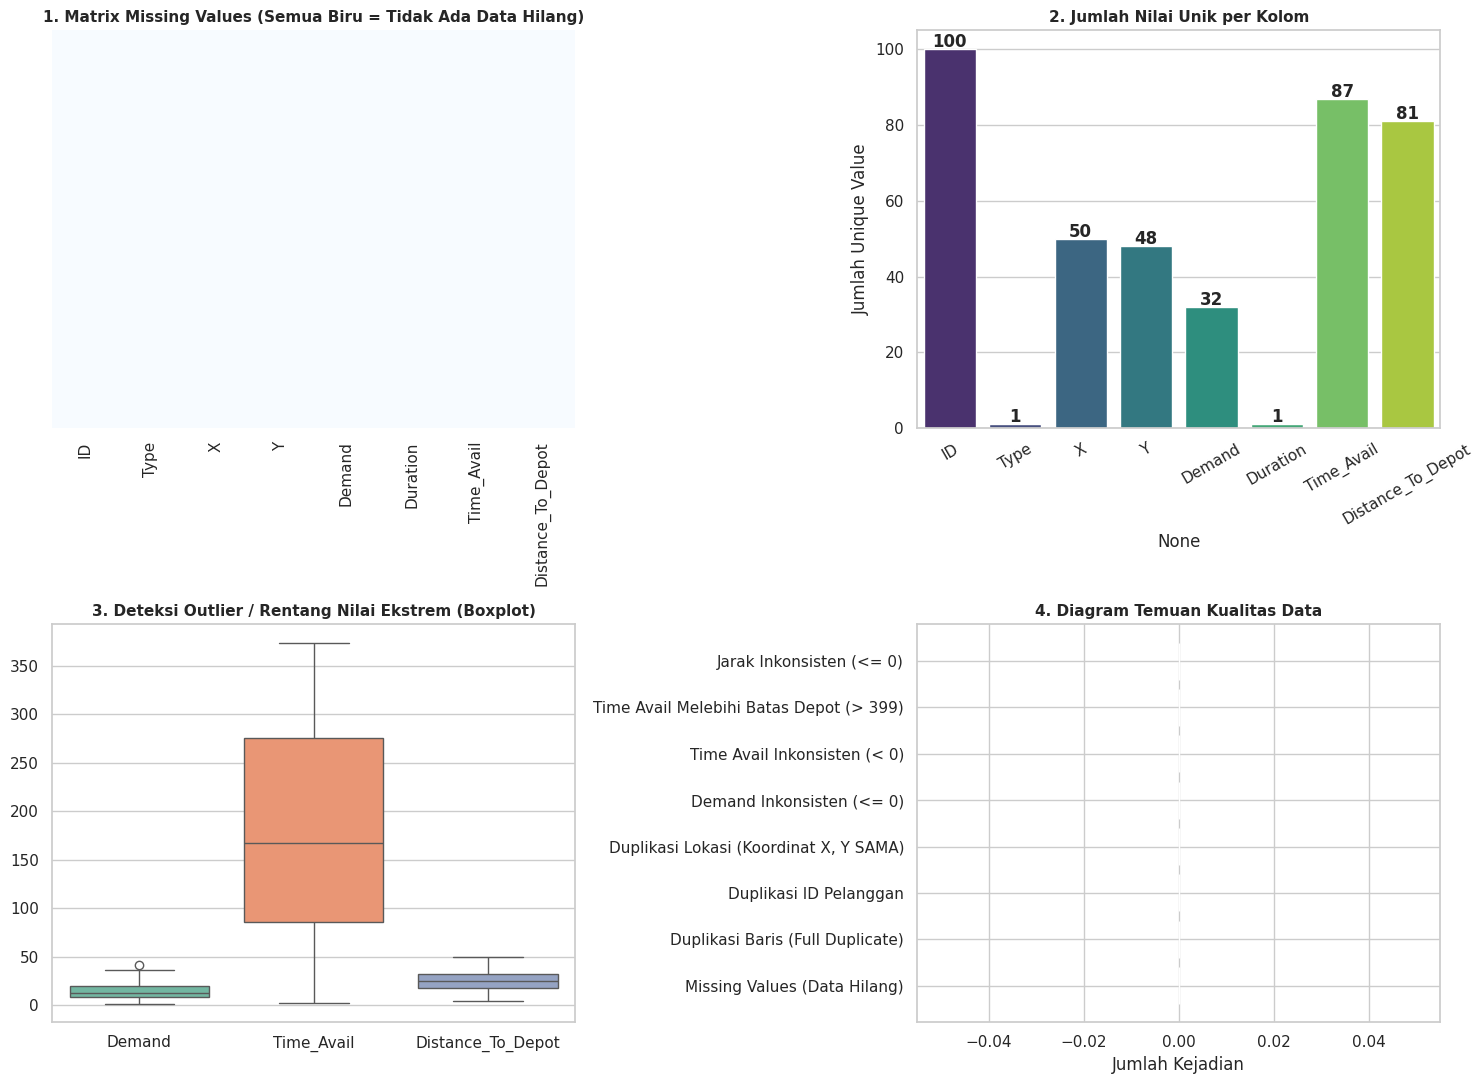

In [2]:
# Struktur & Kualitas Data

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

print("=== 1. UKURAN DATASET (SHAPE) ===")
print(f"Jumlah Baris (Pelanggan) : {customers.shape[0]}")
print(f"Jumlah Kolom              : {customers.shape[1]}")

print("\n=== 2. TIPE DATA & INFORMASI STRUKTUR KOLOM ===")
info_df = pd.DataFrame(
    {
        "Tipe Data": customers.dtypes,
        "Jumlah Non-Null": customers.notnull().sum(),
        "Jumlah Null": customers.isnull().sum(),
        "Persentase Null (%)": (customers.isnull().sum() / len(customers)) * 100,
        "Jumlah Unique Value": customers.nunique(),
    }
)
display(info_df)

print("\n=== 3. RINGKASAN PEMERIKSAAN KUALITAS DATA ===")
missing_count = customers.isnull().sum().sum()

dup_rows = customers.duplicated().sum()
dup_id = customers["ID"].duplicated().sum()
dup_coords = customers.duplicated(subset=["X", "Y"]).sum()

inc_demand = (customers["Demand"] <= 0).sum()
inc_time = (customers["Time_Avail"] < 0).sum()
inc_time_depot = (customers["Time_Avail"] > 399).sum()
inc_dist = (customers["Distance_To_Depot"] <= 0).sum()

kualitas_df = pd.DataFrame({
    "Parameter Identifikasi": [
        "Missing Values (Data Hilang)",
        "Duplikasi Baris (Full Duplicate)",
        "Duplikasi ID Pelanggan",
        "Duplikasi Lokasi (Koordinat X, Y SAMA)",
        "Demand Inkonsisten (<= 0)",
        "Time Avail Inkonsisten (< 0)",
        "Time Avail Melebihi Batas Depot (> 399)",
        "Jarak Inkonsisten (<= 0)",
    ],
    "Jumlah Ditemukan": [
        missing_count,
        dup_rows,
        dup_id,
        dup_coords,
        inc_demand,
        inc_time,
        inc_time_depot,
        inc_dist,
    ],
    "Status": [
        "BERSIH" if missing_count == 0 else "ADA ANOMALI",
        "BERSIH" if dup_rows == 0 else "ADA ANOMALI",
        "BERSIH" if dup_id == 0 else "ADA ANOMALI",
        "PERHATIAN" if dup_coords > 0 else "BERSIH",
        "BERSIH" if inc_demand == 0 else "ADA ANOMALI",
        "BERSIH" if inc_time == 0 else "ADA ANOMALI",
        "BERSIH" if inc_time_depot == 0 else "ADA ANOMALI",
        "BERSIH" if inc_dist == 0 else "ADA ANOMALI",
    ],
})
display(kualitas_df)

if dup_coords > 0:
  print(f"\nCatatan: Terdapat {dup_coords} pelanggan yang berada di titik koordinat yang persis sama dengan pelanggan lain (co-located).")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

sns.heatmap(
    customers.isnull(),
    cbar=False,
    cmap="Blues",
    yticklabels=False,
    ax=axes[0, 0],
)
axes[0, 0].set_title(
    "1. Matrix Missing Values (Semua Biru = Tidak Ada Data Hilang)",
    fontsize=11,
    fontweight="bold",
)

sns.barplot(
    x=info_df.index,
    y=info_df["Jumlah Unique Value"],
    palette="viridis",
    ax=axes[0, 1],
)
axes[0, 1].set_title(
    "2. Jumlah Nilai Unik per Kolom", fontsize=11, fontweight="bold"
)
axes[0, 1].set_xticklabels(axes[0, 1].get_xticklabels(), rotation=30)
for p in axes[0, 1].patches:
  axes[0, 1].annotate(
      f"{int(p.get_height())}",
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha="center",
      va="center",
      xytext=(0, 5),
      textcoords="offset points",
      fontweight="bold",
  )

sns.boxplot(
    data=customers[["Demand", "Time_Avail", "Distance_To_Depot"]],
    palette="Set2",
    ax=axes[1, 0],
)
axes[1, 0].set_title(
    "3. Deteksi Outlier / Rentang Nilai Ekstrem (Boxplot)",
    fontsize=11,
    fontweight="bold",
)

status_colors = [
    "green" if s == "BERSIH" else ("orange" if s == "PERHATIAN" else "red")
    for s in kualitas_df["Status"]
]
axes[1, 1].barh(
    kualitas_df["Parameter Identifikasi"],
    kualitas_df["Jumlah Ditemukan"],
    color=status_colors,
)
axes[1, 1].set_title(
    "4. Diagram Temuan Kualitas Data", fontsize=11, fontweight="bold"
)
axes[1, 1].set_xlabel("Jumlah Kejadian")

plt.tight_layout()
plt.show()

       RINGKASAN STATISTIK DESKRIPTIF & UJI ASUMSI DISTRIBUSI         


,Variabel,Mean,Std Dev,Median,Q1,Q3,IQR,Min,Max,Skewness,Shapiro-Wilk p-val,Distribusi
0,Demand,14.58,8.87,13.00,8.00,19.25,11.25,1.00,41.00,0.69,0.0018,Tidak Normal
1,Time_Avail,179.08,107.44,167.00,85.25,275.25,190.00,2.00,374.00,0.19,0.0007,Tidak Normal
2,Distance_To_Depot,24.95,9.53,24.88,18.03,31.69,13.66,4.47,49.93,0.18,0.7973,Normal


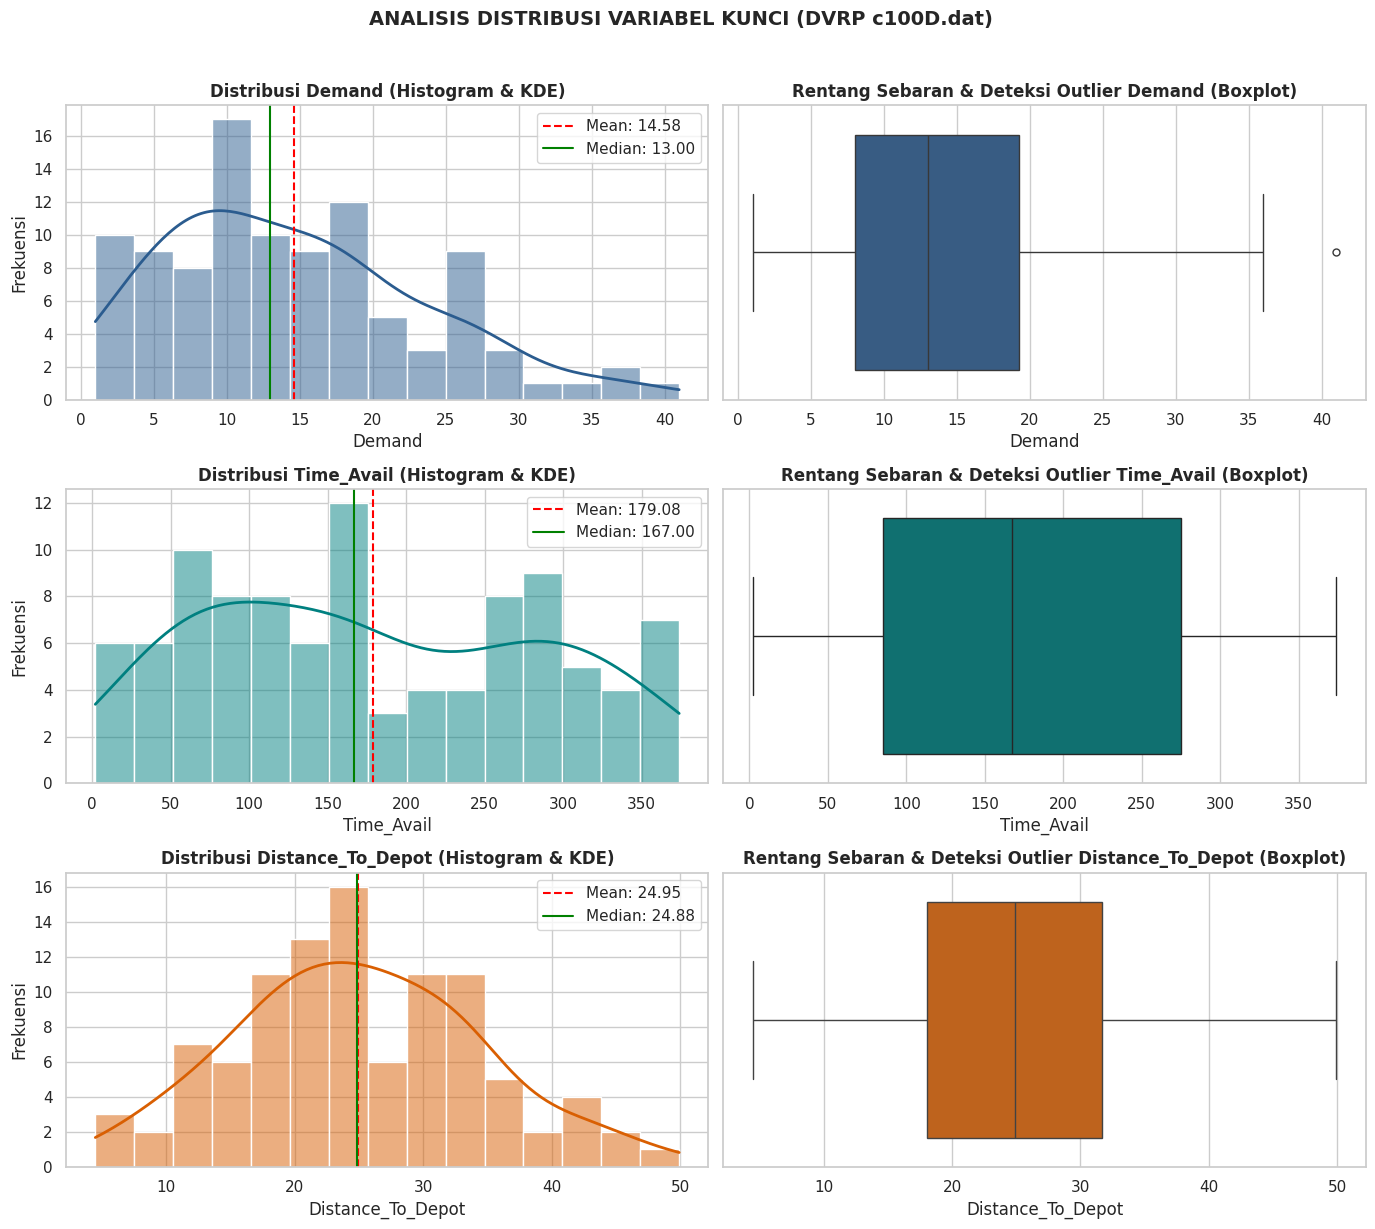

In [3]:
# Statistik Deskriptif

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

var_kunci = ["Demand", "Time_Avail", "Distance_To_Depot"]

summary_list = []
for var in var_kunci:
  data = customers[var]

  mean_val = data.mean()
  std_val = data.std()
  median_val = data.median()
  q1 = data.quantile(0.25)
  q3 = data.quantile(0.75)
  iqr_val = q3 - q1
  min_val = data.min()
  max_val = data.max()
  skew_val = data.skew()

  stat_sw, p_sw = stats.shapiro(data)
  is_normal = "Normal" if p_sw > 0.05 else "Tidak Normal"

  summary_list.append({
      "Variabel": var,
      "Mean": round(mean_val, 2),
      "Std Dev": round(std_val, 2),
      "Median": round(median_val, 2),
      "Q1": round(q1, 2),
      "Q3": round(q3, 2),
      "IQR": round(iqr_val, 2),
      "Min": round(min_val, 2),
      "Max": round(max_val, 2),
      "Skewness": round(skew_val, 2),
      "Shapiro-Wilk p-val": f"{p_sw:.4f}",
      "Distribusi": is_normal,
  })

stats_summary_df = pd.DataFrame(summary_list)

print("======================================================================")
print("       RINGKASAN STATISTIK DESKRIPTIF & UJI ASUMSI DISTRIBUSI         ")
print("======================================================================")
display(stats_summary_df)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
colors = ["#2b5c8f", "#008080", "#d95f02"]

for i, var in enumerate(var_kunci):
  sns.histplot(
      customers[var],
      kde=True,
      ax=axes[i, 0],
      color=colors[i],
      bins=15,
      line_kws={"linewidth": 2},
  )
  axes[i, 0].set_title(
      f"Distribusi {var} (Histogram & KDE)", fontweight="bold"
  )
  axes[i, 0].set_ylabel("Frekuensi")

  axes[i, 0].axvline(
      customers[var].mean(),
      color="red",
      linestyle="--",
      linewidth=1.5,
      label=f"Mean: {customers[var].mean():.2f}",
  )
  axes[i, 0].axvline(
      customers[var].median(),
      color="green",
      linestyle="-",
      linewidth=1.5,
      label=f"Median: {customers[var].median():.2f}",
  )
  axes[i, 0].legend()

  sns.boxplot(x=customers[var], ax=axes[i, 1], color=colors[i], fliersize=5)
  axes[i, 1].set_title(
      f"Rentang Sebaran & Deteksi Outlier {var} (Boxplot)", fontweight="bold"
  )
  axes[i, 1].set_xlabel(var)

plt.suptitle(
    "ANALISIS DISTRIBUSI VARIABEL KUNCI (DVRP c100D.dat)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

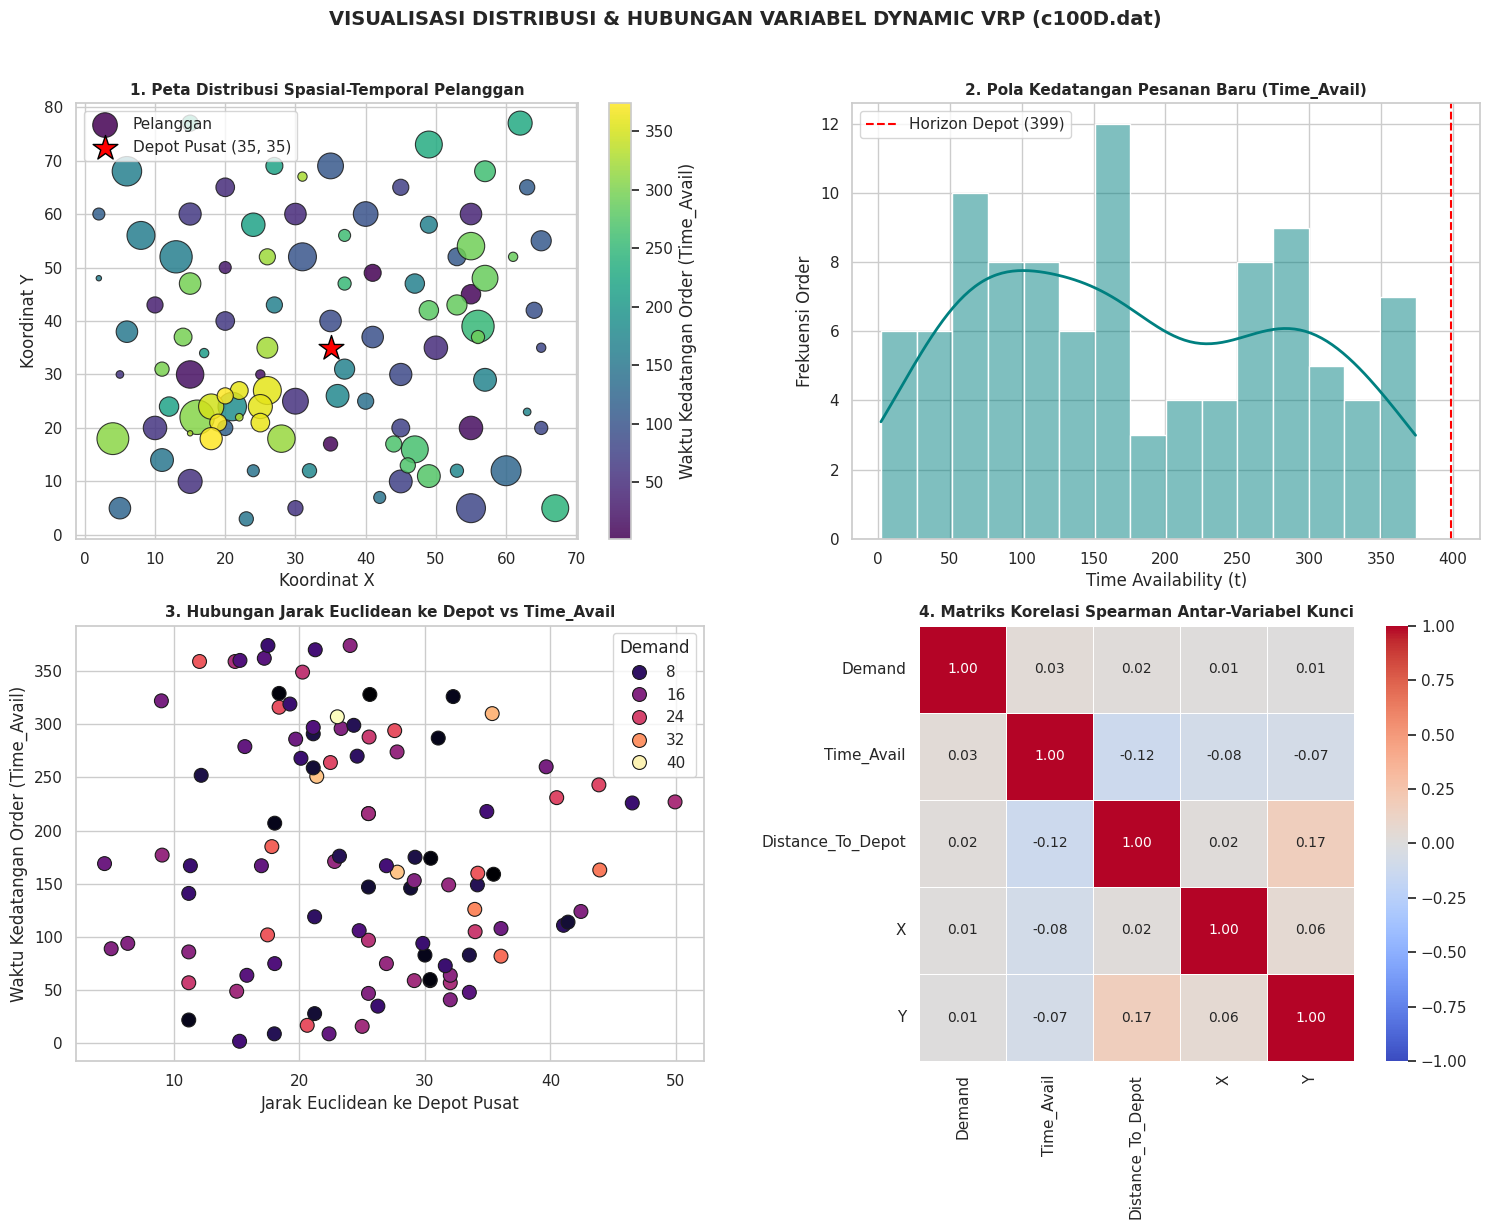

In [4]:
#Visualisasi Distribusi & Hubungan Variabel

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

depot = df[df["Type"] == "Depot"].iloc[0]
customers = df[df["Type"] == "Customer"].copy()

customers["Distance_To_Depot"] = np.sqrt(
    (customers["X"] - depot["X"]) ** 2 + (customers["Y"] - depot["Y"]) ** 2
).round(2)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

scatter1 = axes[0, 0].scatter(
    customers["X"],
    customers["Y"],
    c=customers["Time_Avail"],
    cmap="viridis",
    s=customers["Demand"] * 15,
    alpha=0.85,
    edgecolors="k",
    linewidths=0.8,
    label="Pelanggan",
)
axes[0, 0].scatter(
    depot["X"],
    depot["Y"],
    color="red",
    marker="*",
    s=350,
    edgecolors="black",
    label=f"Depot Pusat ({depot['X']}, {depot['Y']})",
)
axes[0, 0].set_title(
    "1. Peta Distribusi Spasial-Temporal Pelanggan",
    fontsize=11,
    fontweight="bold",
)
axes[0, 0].set_xlabel("Koordinat X")
axes[0, 0].set_ylabel("Koordinat Y")
cbar1 = fig.colorbar(scatter1, ax=axes[0, 0])
cbar1.set_label("Waktu Kedatangan Order (Time_Avail)")
axes[0, 0].legend(loc="upper left")

sns.histplot(
    customers["Time_Avail"],
    kde=True,
    bins=15,
    ax=axes[0, 1],
    color="teal",
    line_kws={"linewidth": 2},
)
axes[0, 1].axvline(
    399, color="red", linestyle="--", linewidth=1.5, label="Horizon Depot (399)"
)
axes[0, 1].set_title(
    "2. Pola Kedatangan Pesanan Baru (Time_Avail)",
    fontsize=11,
    fontweight="bold",
)
axes[0, 1].set_xlabel("Time Availability (t)")
axes[0, 1].set_ylabel("Frekuensi Order")
axes[0, 1].legend()

sns.scatterplot(
    data=customers,
    x="Distance_To_Depot",
    y="Time_Avail",
    hue="Demand",
    palette="magma",
    s=100,
    ax=axes[1, 0],
    edgecolor="k",
)
axes[1, 0].set_title(
    "3. Hubungan Jarak Euclidean ke Depot vs Time_Avail",
    fontsize=11,
    fontweight="bold",
)
axes[1, 0].set_xlabel("Jarak Euclidean ke Depot Pusat")
axes[1, 0].set_ylabel("Waktu Kedatangan Order (Time_Avail)")

var_korelasi = ["Demand", "Time_Avail", "Distance_To_Depot", "X", "Y"]
corr_matrix = customers[var_korelasi].corr(method="spearman")

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1, 1],
    cbar=True,
    square=True,
    linewidths=0.5,
)
axes[1, 1].set_title(
    "4. Matriks Korelasi Spearman Antar-Variabel Kunci",
    fontsize=11,
    fontweight="bold",
)

plt.suptitle(
    "VISUALISASI DISTRIBUSI & HUBUNGAN VARIABEL DYNAMIC VRP (c100D.dat)",
    fontsize=14,
    fontweight="bold",
    y=1.02,
)
plt.tight_layout()
plt.show()

                 HASIL PERBANDINGAN DETEKSI OUTLIER (METODE IQR VS Z-SCORE)             


,Variabel,Q1,Q3,IQR,Batas Bawah (IQR),Batas Atas (IQR),Outlier IQR (N),Node ID (IQR),Outlier Z-Score (N),Node ID (Z-Score)
0,Demand,8.00,19.25,11.25,-8.88,36.12,1,[85],0,-
1,Time_Avail,85.25,275.25,190.00,-199.75,560.25,0,-,0,-
2,Distance_To_Depot,18.03,31.69,13.66,-2.46,52.17,0,-,0,-



=== DETAIL NODE OUTLIER PADA VARIABEL DEMAND ===


,ID,X,Y,Demand,Time_Avail,Distance_To_Depot
85,85,16,22,41,307,23.02


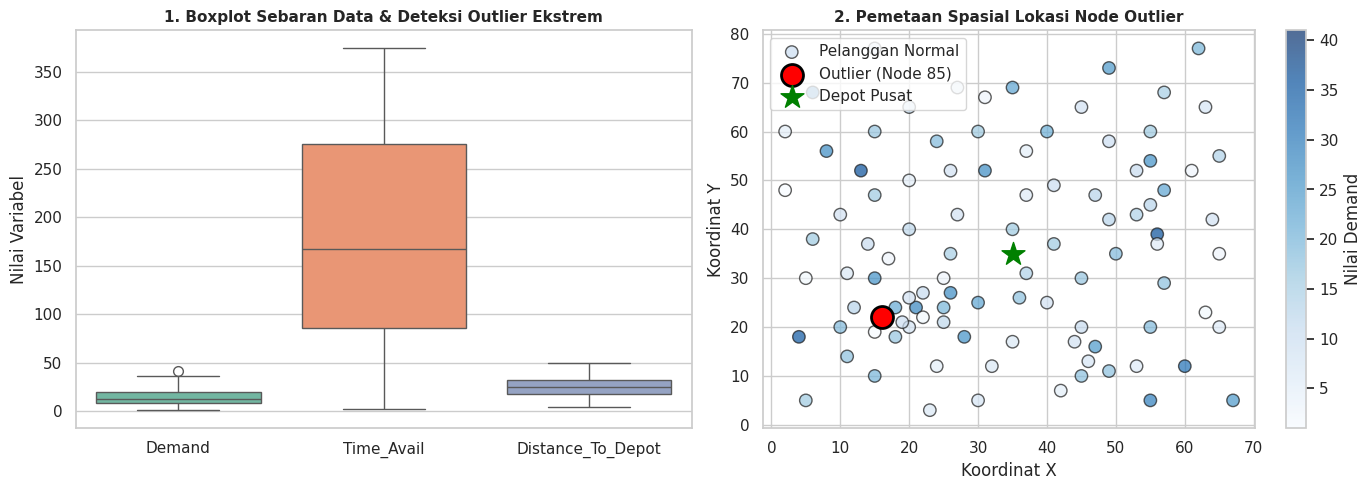

In [5]:
#	Deteksi Outlier / Anomali

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 10, "figure.autolayout": True})

customers = df[df["Type"] == "Customer"].copy()

depot = df[df["Type"] == "Depot"].iloc[0]
customers["Distance_To_Depot"] = np.sqrt(
    (customers["X"] - depot["X"]) ** 2 + (customers["Y"] - depot["Y"]) ** 2
).round(2)

var_kunci = ["Demand", "Time_Avail", "Distance_To_Depot"]

outlier_summary = []

for var in var_kunci:
  data = customers[var]

  q1 = data.quantile(0.25)
  q3 = data.quantile(0.75)
  iqr = q3 - q1
  lower_bound_iqr = q1 - 1.5 * iqr
  upper_bound_iqr = q3 + 1.5 * iqr

  iqr_outliers = customers[
      (data < lower_bound_iqr) | (data > upper_bound_iqr)
  ]
  count_iqr = len(iqr_outliers)
  ids_iqr = iqr_outliers["ID"].tolist() if count_iqr > 0 else "-"

  z_scores = np.abs(stats.zscore(data))
  z_outliers = customers[z_scores > 3.0]
  count_z = len(z_outliers)
  ids_z = z_outliers["ID"].tolist() if count_z > 0 else "-"

  outlier_summary.append({
      "Variabel": var,
      "Q1": round(q1, 2),
      "Q3": round(q3, 2),
      "IQR": round(iqr, 2),
      "Batas Bawah (IQR)": round(lower_bound_iqr, 2),
      "Batas Atas (IQR)": round(upper_bound_iqr, 2),
      "Outlier IQR (N)": count_iqr,
      "Node ID (IQR)": ids_iqr,
      "Outlier Z-Score (N)": count_z,
      "Node ID (Z-Score)": ids_z,
  })

outlier_df = pd.DataFrame(outlier_summary)

print("========================================================================================")
print("                 HASIL PERBANDINGAN DETEKSI OUTLIER (METODE IQR VS Z-SCORE)             ")
print("========================================================================================")
display(outlier_df)

if len(customers[customers["Demand"] > outlier_df.loc[0, "Batas Atas (IQR)"]]) > 0:
  print("\n=== DETAIL NODE OUTLIER PADA VARIABEL DEMAND ===")
  display(
      customers[
          customers["Demand"] > outlier_df.loc[0, "Batas Atas (IQR)"]
      ][["ID", "X", "Y", "Demand", "Time_Avail", "Distance_To_Depot" ]]
  )

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=customers[["Demand", "Time_Avail", "Distance_To_Depot"]],
    palette="Set2",
    ax=axes[0],
    fliersize=7,
)
axes[0].set_title(
    "1. Boxplot Sebaran Data & Deteksi Outlier Ekstrem",
    fontsize=11,
    fontweight="bold",
)
axes[0].set_ylabel("Nilai Variabel")

scatter = axes[1].scatter(
    customers["X"],
    customers["Y"],
    c=customers["Demand"],
    cmap="Blues",
    s=80,
    alpha=0.7,
    edgecolors="k",
    label="Pelanggan Normal",
)

outlier_nodes = customers[
    customers["Demand"] > outlier_df.loc[0, "Batas Atas (IQR)"]
]
axes[1].scatter(
    outlier_nodes["X"],
    outlier_nodes["Y"],
    color="red",
    s=250,
    marker="o",
    edgecolors="black",
    linewidths=2,
    label=f"Outlier (Node {outlier_nodes['ID'].values[0]})",
)

axes[1].scatter(
    depot["X"],
    depot["Y"],
    color="green",
    marker="*",
    s=300,
    label="Depot Pusat",
)

axes[1].set_title(
    "2. Pemetaan Spasial Lokasi Node Outlier", fontsize=11, fontweight="bold"
)
axes[1].set_xlabel("Koordinat X")
axes[1].set_ylabel("Koordinat Y")
plt.colorbar(scatter, ax=axes[1], label="Nilai Demand")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()